# 04 · Análise de sensibilidade ao preço da energia

A versão submetida do Artigo 1 continha uma seção (7.6, Figuras 4-9) com a sensibilidade
dos projetos ao preço da energia, removida na versão publicada. O código Scilab original
(`otimizaRede13_sensib.sci`) varria o preço de 0.0025 a 0.20 USD/kWh. Reproduzimos aqui
essa análise com `cwnet.design.sensitivity.energy_price_sweep`.

No método de Edgar & Himmelblau o diâmetro econômico escala com `pc^0.164`, como no
código original.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cwnet import load_case, run_design_study
from cwnet.reporting import plots, tables

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
CASES = Path("../cases")

In [2]:
from cwnet.design.sensitivity import energy_price_sweep
case = load_case(CASES / "paper1_grassroots.yaml")
prices = np.round(np.arange(0.01, 0.2001, 0.01), 4)
df = energy_price_sweep(case, prices)
df.head()

,energy_price,traditional_edgar_himmelblau_total,traditional_edgar_himmelblau_operating,traditional_edgar_himmelblau_pump,traditional_edgar_himmelblau_pipe,traditional_towler_total,traditional_towler_operating,traditional_towler_pump,traditional_towler_pipe,lp_Curve 1_total,lp_Curve 1_operating,lp_Curve 1_pump,lp_Curve 1_pipe,lp_Curve 2_total,lp_Curve 2_operating,lp_Curve 2_pump,lp_Curve 2_pipe,lp_Curve 3_total,lp_Curve 3_operating,lp_Curve 3_pump,lp_Curve 3_pipe,lp_Curve 4_total,lp_Curve 4_operating,lp_Curve 4_pump,lp_Curve 4_pipe,best_pump,best_total,best_operating,best_pump_cost,best_pipe
0,0.01,16052.531056,3024.049014,3409.454828,9619.027214,25436.055076,1942.024837,3044.574185,20449.456054,21643.644911,2018.292458,3044.574185,16580.778268,19968.496088,2421.950949,3209.340017,14337.205122,19716.789505,2691.056610,3311.826057,13713.906838,19649.132262,2960.162271,3409.454828,13279.515163,Curve 4,19649.132262,2960.162271,3409.454828,13279.515163
1,0.02,20143.649663,6045.760067,3409.454828,10688.434768,27378.079913,3884.049674,3044.574185,20449.456054,23661.937369,4036.584915,3044.574185,16580.778268,22390.447038,4843.901899,3209.340017,14337.205122,22407.846115,5382.113221,3311.826057,13713.906838,22609.294533,5920.324543,3409.454828,13279.515163,Curve 2,22390.447038,4843.901899,3209.340017,14337.205122
2,0.03,25066.971652,8623.601156,3409.454828,13033.915668,29320.104750,5826.074511,3044.574185,20449.456054,25680.229826,6054.877373,3044.574185,16580.778268,24812.397987,7265.852848,3209.340017,14337.205122,25098.902726,8073.169831,3311.826057,13713.906838,25569.456805,8880.486814,3409.454828,13279.515163,Curve 2,24812.397987,7265.852848,3209.340017,14337.205122
3,0.04,28290.853092,11389.361707,3409.454828,13492.036556,31262.129587,7768.099348,3044.574185,20449.456054,27698.522284,8073.169831,3044.574185,16580.778268,27234.348936,9687.803797,3209.340017,14337.205122,27789.959336,10764.226441,3311.826057,13713.906838,28529.619076,11840.649085,3409.454828,13279.515163,Curve 2,27234.348936,9687.803797,3209.340017,14337.205122
4,0.05,31138.193519,14236.702134,3409.454828,13492.036556,33204.154424,9710.124185,3044.574185,20449.456054,29716.814742,10091.462289,3044.574185,16580.778268,29656.299885,12109.754746,3209.340017,14337.205122,30481.015946,13455.283052,3311.826057,13713.906838,31489.781347,14800.811357,3409.454828,13279.515163,Curve 2,29656.299885,12109.754746,3209.340017,14337.205122


## Figura 4 — função objetivo ótima de cada curva de bomba

melhor bomba por preço:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
energy_price,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.1,0.11,0.12,0.13,0.14,0.15,0.16,0.17,0.18,0.19,0.2
best_pump,Curve 4,Curve 2,Curve 2,Curve 2,Curve 2,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1,Curve 1
best_total,19649.132262,22390.447038,24812.397987,27234.348936,29656.299885,31735.107199,33753.399657,35771.692115,37789.984573,39808.27703,41826.569488,43844.861946,45863.154404,47881.446861,49899.739319,51918.031777,53936.324234,55954.616692,57972.90915,59991.201608


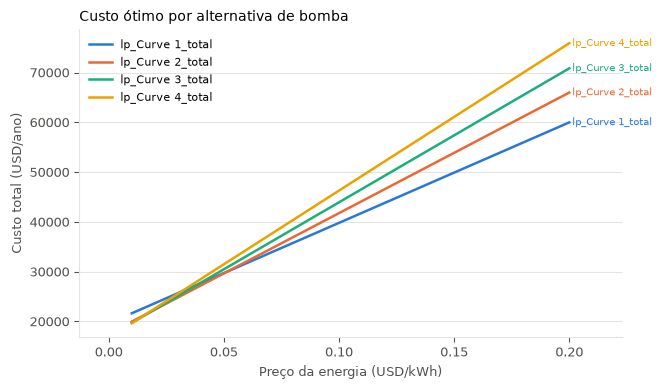

In [3]:
pumps = [c.tag for c in case.pump_catalog]
ax = plots.plot_sensitivity(df, "energy_price", [f"lp_{p}_total" for p in pumps], xlabel="Preço da energia (USD/kWh)",
                            ylabel="Custo total (USD/ano)", title="Custo ótimo por alternativa de bomba")
print("melhor bomba por preço:"); display(df[["energy_price", "best_pump", "best_total"]].T)

## Figuras 5 e 6 — projeto proposto × métodos tradicionais e redução de custo

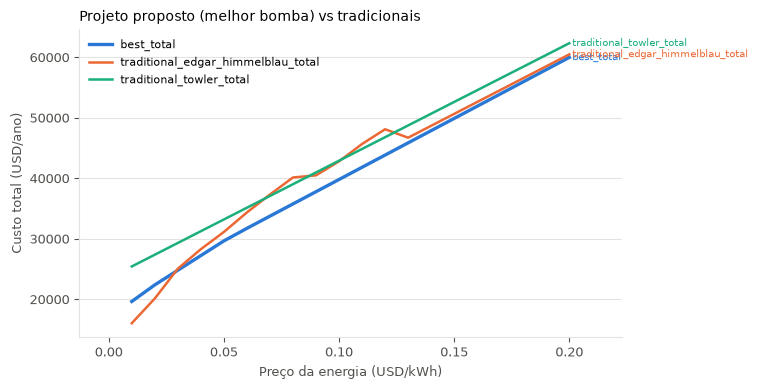

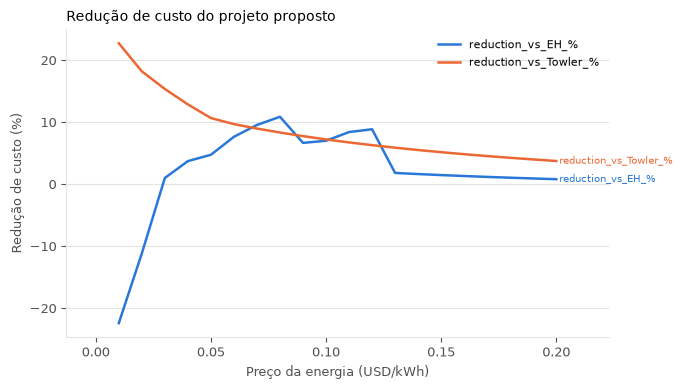

In [4]:
ax = plots.plot_sensitivity(df, "energy_price", ["best_total", "traditional_edgar_himmelblau_total", "traditional_towler_total"],
                            xlabel="Preço da energia (USD/kWh)", ylabel="Custo total (USD/ano)",
                            title="Projeto proposto (melhor bomba) vs tradicionais", highlight="best_total")
df["reduction_vs_EH_%"] = 100 * (1 - df["best_total"] / df["traditional_edgar_himmelblau_total"])
df["reduction_vs_Towler_%"] = 100 * (1 - df["best_total"] / df["traditional_towler_total"])
ax2 = plots.plot_sensitivity(df, "energy_price", ["reduction_vs_EH_%", "reduction_vs_Towler_%"],
                             xlabel="Preço da energia (USD/kWh)", ylabel="Redução de custo (%)", title="Redução de custo do projeto proposto")

## Figuras 7, 8 e 9 — custos operacionais, de bomba e de tubos

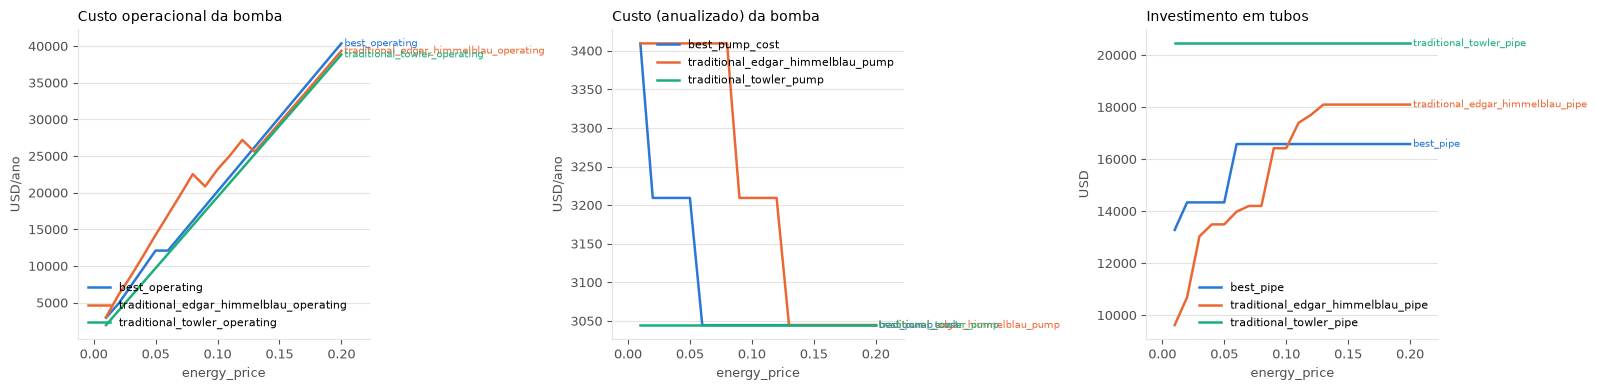

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plots.plot_sensitivity(df, "energy_price", ["best_operating", "traditional_edgar_himmelblau_operating", "traditional_towler_operating"], ax=axes[0], ylabel="USD/ano", title="Custo operacional da bomba")
plots.plot_sensitivity(df, "energy_price", ["best_pump_cost", "traditional_edgar_himmelblau_pump", "traditional_towler_pump"], ax=axes[1], ylabel="USD/ano", title="Custo (anualizado) da bomba")
plots.plot_sensitivity(df, "energy_price", ["best_pipe", "traditional_edgar_himmelblau_pipe", "traditional_towler_pipe"], ax=axes[2], ylabel="USD", title="Investimento em tubos")
plt.tight_layout()

In [6]:
df.round(0)

,energy_price,traditional_edgar_himmelblau_total,traditional_edgar_himmelblau_operating,traditional_edgar_himmelblau_pump,traditional_edgar_himmelblau_pipe,traditional_towler_total,traditional_towler_operating,traditional_towler_pump,traditional_towler_pipe,lp_Curve 1_total,lp_Curve 1_operating,lp_Curve 1_pump,lp_Curve 1_pipe,lp_Curve 2_total,lp_Curve 2_operating,...,lp_Curve 3_total,lp_Curve 3_operating,lp_Curve 3_pump,lp_Curve 3_pipe,lp_Curve 4_total,lp_Curve 4_operating,lp_Curve 4_pump,lp_Curve 4_pipe,best_pump,best_total,best_operating,best_pump_cost,best_pipe,reduction_vs_EH_%,reduction_vs_Towler_%
0,0.0,16053.0,3024.0,3409.0,9619.0,25436.0,1942.0,3045.0,20449.0,21644.0,2018.0,3045.0,16581.0,19968.0,2422.0,...,19717.0,2691.0,3312.0,13714.0,19649.0,2960.0,3409.0,13280.0,Curve 4,19649.0,2960.0,3409.0,13280.0,-22.0,23.0
1,0.0,20144.0,6046.0,3409.0,10688.0,27378.0,3884.0,3045.0,20449.0,23662.0,4037.0,3045.0,16581.0,22390.0,4844.0,...,22408.0,5382.0,3312.0,13714.0,22609.0,5920.0,3409.0,13280.0,Curve 2,22390.0,4844.0,3209.0,14337.0,-11.0,18.0
2,0.0,25067.0,8624.0,3409.0,13034.0,29320.0,5826.0,3045.0,20449.0,25680.0,6055.0,3045.0,16581.0,24812.0,7266.0,...,25099.0,8073.0,3312.0,13714.0,25569.0,8880.0,3409.0,13280.0,Curve 2,24812.0,7266.0,3209.0,14337.0,1.0,15.0
3,0.0,28291.0,11389.0,3409.0,13492.0,31262.0,7768.0,3045.0,20449.0,27699.0,8073.0,3045.0,16581.0,27234.0,9688.0,...,27790.0,10764.0,3312.0,13714.0,28530.0,11841.0,3409.0,13280.0,Curve 2,27234.0,9688.0,3209.0,14337.0,4.0,13.0
4,0.0,31138.0,14237.0,3409.0,13492.0,33204.0,9710.0,3045.0,20449.0,29717.0,10091.0,3045.0,16581.0,29656.0,12110.0,...,30481.0,13455.0,3312.0,13714.0,31490.0,14801.0,3409.0,13280.0,Curve 2,29656.0,12110.0,3209.0,14337.0,5.0,11.0
5,0.0,34367.0,16974.0,3409.0,13983.0,35146.0,11652.0,3045.0,20449.0,31735.0,12110.0,3045.0,16581.0,32078.0,14532.0,...,33172.0,16146.0,3312.0,13714.0,34450.0,17761.0,3409.0,13280.0,Curve 1,31735.0,12110.0,3045.0,16581.0,8.0,10.0
6,0.0,37326.0,19714.0,3409.0,14202.0,37088.0,13594.0,3045.0,20449.0,33753.0,14128.0,3045.0,16581.0,34500.0,16954.0,...,35863.0,18837.0,3312.0,13714.0,37410.0,20721.0,3409.0,13280.0,Curve 1,33753.0,14128.0,3045.0,16581.0,10.0,9.0
7,0.0,40142.0,22531.0,3409.0,14202.0,39030.0,15536.0,3045.0,20449.0,35772.0,16146.0,3045.0,16581.0,36922.0,19376.0,...,38554.0,21528.0,3312.0,13714.0,40370.0,23681.0,3409.0,13280.0,Curve 1,35772.0,16146.0,3045.0,16581.0,11.0,8.0
8,0.0,40495.0,20866.0,3209.0,16420.0,40972.0,17478.0,3045.0,20449.0,37790.0,18165.0,3045.0,16581.0,39344.0,21798.0,...,41245.0,24220.0,3312.0,13714.0,43330.0,26641.0,3409.0,13280.0,Curve 1,37790.0,18165.0,3045.0,16581.0,7.0,8.0
9,0.0,42813.0,23184.0,3209.0,16420.0,42914.0,19420.0,3045.0,20449.0,39808.0,20183.0,3045.0,16581.0,41766.0,24220.0,...,43936.0,26911.0,3312.0,13714.0,46291.0,29602.0,3409.0,13280.0,Curve 1,39808.0,20183.0,3045.0,16581.0,7.0,7.0
